# Segmentación de clientes mediante K-Means
**Aprendizaje Automático – Clase 8**

## Objetivo
Aplicar el algoritmo de aprendizaje no supervisado K-Means para identificar grupos de clientes con comportamientos de compra similares.

## Preparación de los datos
El dataset contiene 700 registros y 7 variables numéricas, sin valores faltantes.

Para el análisis seleccionaremos las cinco variables relacionadas con el comportamiento de los clientes: frecuencia de compras, importe promedio, tiempo de permanencia en el sitio, sensibilidad a descuentos y tasa de devoluciones.

**Excluiremos las columnas `noise_gauss` y `noise_uniform`**, porque contienen ruido artificial y no representan características relevantes del comportamiento de compra. Su inclusión podría afectar la formación de los clústeres.

Posteriormente, escalaremos las variables y aplicaremos K-Means para comparar entre 2 y 6 grupos mediante el método del codo.

In [1]:
import pandas as pd

df = pd.read_csv('/content/dataset_segmentacion_clientes.csv')

df.head()

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,noise_gauss,noise_uniform
0,11.152508,181.300834,33.564036,1.000000,0.800000,-1.806578,-2.516905
1,12.053451,178.637272,35.432081,0.784974,0.000000,0.645129,2.115460
2,2.203006,450.185298,7.030757,0.898297,0.000000,-0.047406,-0.724173
3,4.233314,89.006342,10.834453,0.000000,0.800000,0.901700,-2.974026
4,1.716799,449.773982,7.254548,0.000000,0.003279,0.386013,2.424522


In [2]:
print("Filas y columnas:", df.shape)
df.info()

Filas y columnas: (700, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   purchase_freq_month   700 non-null    float64
 1   avg_basket_usd        700 non-null    float64
 2   time_on_site_min      700 non-null    float64
 3   discount_sensitivity  700 non-null    float64
 4   returns_rate          700 non-null    float64
 5   noise_gauss           700 non-null    float64
 6   noise_uniform         700 non-null    float64
dtypes: float64(7)
memory usage: 38.4 KB


In [3]:
# Seleccionar las variables relevantes para K-Means

columnas = [
    'purchase_freq_month',
    'avg_basket_usd',
    'time_on_site_min',
    'discount_sensitivity',
    'returns_rate'
]

X = df[columnas].copy()

# Mostrar las primeras cinco filas
X.head()

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
0,11.152508,181.300834,33.564036,1.000000,0.800000
1,12.053451,178.637272,35.432081,0.784974,0.000000
2,2.203006,450.185298,7.030757,0.898297,0.000000
3,4.233314,89.006342,10.834453,0.000000,0.800000
4,1.716799,449.773982,7.254548,0.000000,0.003279


## Escalado de variables

Antes de aplicar K-Means, utilizamos StandardScaler para estandarizar las cinco variables seleccionadas.

Este procedimiento transforma las variables para que tengan media 0 y desviación estándar 1, evitando que aquellas con valores numéricos más grandes dominen el cálculo de las distancias entre clientes.

In [4]:
from sklearn.preprocessing import StandardScaler

# Estandarizar las cinco variables
scaler = StandardScaler()
X_escalado = scaler.fit_transform(X)

# Mostrar las primeras cinco filas
pd.DataFrame(X_escalado, columns=columnas).head()

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
0,1.181048,-0.432012,1.300224,1.333423,1.298671
1,1.382696,-0.449219,1.444979,0.834706,-0.946196
2,-0.822026,1.305039,-0.755841,1.097540,-0.946196
3,-0.367604,-1.028253,-0.461093,-0.985910,1.298671
4,-0.930849,1.302382,-0.738500,-0.985910,-0.936996


## Determinación del número de clústeres: método del codo

Aplicaremos K-Means con valores de K entre 2 y 6, tal como solicita la consigna.

Para cada valor calcularemos la inercia, que representa la suma de las distancias al cuadrado entre los datos y los centroides de sus respectivos grupos.

Mediante el gráfico del codo buscaremos identificar el punto a partir del cual aumentar la cantidad de clústeres produce una reducción cada vez menor de la inercia.

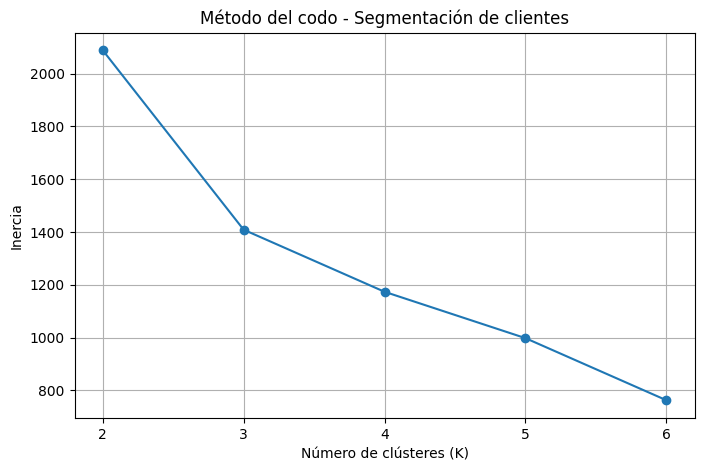

In [5]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Calcular la inercia para K entre 2 y 6
inercias = []

for k in range(2, 7):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    modelo.fit(X_escalado)
    inercias.append(modelo.inertia_)

# Graficar el método del codo
plt.figure(figsize=(8, 5))
plt.plot(range(2, 7), inercias, marker='o')
plt.xlabel('Número de clústeres (K)')
plt.ylabel('Inercia')
plt.title('Método del codo - Segmentación de clientes')
plt.xticks(range(2, 7))
plt.grid(True)
plt.show()

### Interpretación del método del codo

El gráfico muestra una disminución importante de la inercia al pasar de 2 a 3 clústeres.

A partir de K = 3, la reducción de la inercia es menos pronunciada.

Por este motivo, seleccionamos provisionalmente **K = 3** como una cantidad razonable de grupos para segmentar los clientes.

Posteriormente analizaremos los centroides para comprobar si los grupos obtenidos presentan características diferenciadas e interpretables.

## Aplicación del modelo K-Means

Aplicaremos el algoritmo K-Means utilizando tres clústeres, seleccionados a partir del método del codo.

El modelo agrupará automáticamente los 700 clientes según sus semejanzas en las cinco variables estandarizadas.

Cada cliente recibirá una etiqueta numérica (0, 1 o 2) que identificará el grupo al que pertenece.

In [6]:
# Entrenar K-Means con 3 clústeres
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Entrenar y asignar los grupos
df['cluster'] = kmeans.fit_predict(X_escalado)

# Mostrar los primeros clientes y sus grupos
df[columnas + ['cluster']].head()

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,cluster
0,11.152508,181.300834,33.564036,1.000000,0.800000,0
1,12.053451,178.637272,35.432081,0.784974,0.000000,0
2,2.203006,450.185298,7.030757,0.898297,0.000000,1
3,4.233314,89.006342,10.834453,0.000000,0.800000,2
4,1.716799,449.773982,7.254548,0.000000,0.003279,1


## Distribución de clientes por clúster

Analizaremos cuántos clientes fueron asignados a cada uno de los tres grupos identificados por K-Means.

Esto permitirá conocer el tamaño de cada segmento y su proporción respecto del total de 700 clientes.

In [8]:
# Contar clientes por clúster
conteo = df['cluster'].value_counts().sort_index()

# Calcular porcentajes
porcentajes = df['cluster'].value_counts(
    normalize=True
).sort_index() * 100

# Mostrar resultados
resumen = pd.DataFrame({
    'Cantidad de clientes': conteo,
    'Porcentaje (%)': porcentajes.round(2)
})

resumen

,Cantidad de clientes,Porcentaje (%)
cluster,,
0,230,32.86
1,250,35.71
2,220,31.43


## Análisis de los centroides

Calcularemos los valores promedio de las cinco variables para cada clúster.

Este análisis permitirá identificar las características de los clientes de cada grupo y describir sus diferentes comportamientos de compra.

Utilizaremos los valores originales de las variables para facilitar su interpretación.

In [9]:
# Calcular los valores promedio de cada grupo
centroides = df.groupby('cluster')[columnas].mean()

# Mostrar los resultados con dos decimales
centroides.round(2)

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
cluster,,,,,
0,11.96,180.00,35.02,0.54,0.33
1,1.85,450.12,5.97,0.36,0.38
2,4.09,89.96,10.00,0.38,0.30


### Interpretación de los segmentos identificados

El algoritmo K-Means permitió identificar tres perfiles de clientes:

**Clúster 0 – Compradores frecuentes (230 clientes, 32,86 %)**

Realizan aproximadamente 12 compras mensuales, con un importe promedio de 180 USD. Permanecen más tiempo en el sitio web y presentan la mayor sensibilidad a descuentos. Podrían ser destinatarios de promociones y programas de fidelización.

**Clúster 1 – Compradores de alto valor (250 clientes, 35,71 %)**

Realizan aproximadamente 2 compras mensuales, pero presentan el importe promedio más alto (450,12 USD). Podrían ser destinatarios de ofertas de productos premium.

**Clúster 2 – Compradores de menor gasto (220 clientes, 31,43 %)**

Realizan aproximadamente 4 compras mensuales, con un importe promedio de 89,96 USD. Presentan la menor tasa de devoluciones. Podrían ser destinatarios de estrategias para incrementar el valor de sus compras.

**Conclusión:** K-Means permitió identificar tres segmentos con diferentes hábitos de compra. Estos resultados pueden ayudar a diseñar estrategias comerciales adaptadas a cada grupo.

## Visualización de la distribución de clientes

Representaremos mediante un gráfico de barras la cantidad de clientes pertenecientes a cada clúster.

Esto permitirá comparar visualmente el tamaño de los tres segmentos identificados por K-Means.

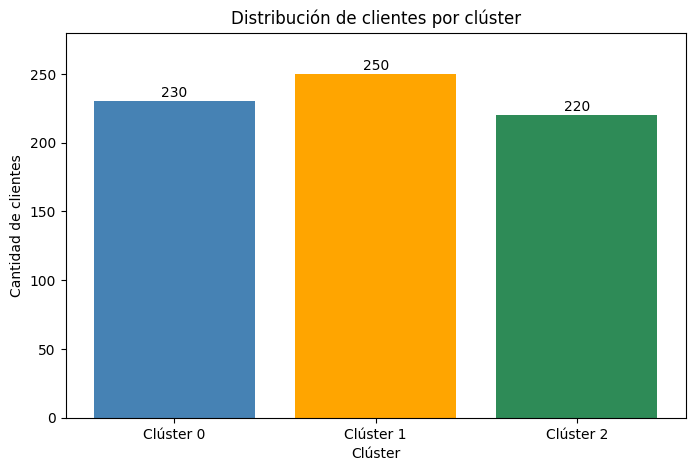

In [11]:
# Gráfico de distribución de clientes
plt.figure(figsize=(8, 5))

barras = plt.bar(
    ['Clúster 0', 'Clúster 1', 'Clúster 2'],
    conteo.values,
    color=['steelblue', 'orange', 'seagreen']
)

plt.title('Distribución de clientes por clúster')
plt.xlabel('Clúster')
plt.ylabel('Cantidad de clientes')

# Mostrar cantidades sobre las barras
for barra in barras:
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 3,
        str(int(barra.get_height())),
        ha='center'
    )

plt.ylim(0, 280)
plt.show()

## Conclusión final

En este trabajo aplicamos el algoritmo de aprendizaje no supervisado K-Means para segmentar 700 clientes según cinco características de sus hábitos de compra.

Primero seleccionamos las variables relevantes y realizamos su estandarización mediante StandardScaler, evitando que las diferencias de escala influyeran excesivamente en los resultados.

Posteriormente, aplicamos el método del codo, comparando valores de K entre 2 y 6. El análisis sugirió utilizar tres clústeres.

El modelo identificó tres segmentos:

- **Clúster 0:** 230 clientes (32,86 %), caracterizados por compras frecuentes y mayor sensibilidad a descuentos.
- **Clúster 1:** 250 clientes (35,71 %), con compras menos frecuentes, pero de mayor importe.
- **Clúster 2:** 220 clientes (31,43 %), con compras de menor importe y menor tasa de devoluciones.

El análisis de los centroides permitió interpretar las características de cada segmento y proponer posibles estrategias comerciales diferenciadas.

**En conclusión**, K-Means permitió descubrir patrones de comportamiento sin utilizar etiquetas previas. Los resultados muestran cómo el aprendizaje no supervisado puede contribuir a la segmentación de clientes y apoyar la toma de decisiones comerciales.